# Florence-2: captions, detection and phrase grounding from one model

Classic perception stacks run one network per task: a captioner, a detector, a grounding
model, an OCR engine. **Florence-2** replaces them with a single 0.23 B-parameter
sequence-to-sequence model. A *text prompt* selects the task, and the answer comes back as text,
even when the answer is a set of boxes, because coordinates are emitted as special
*location tokens*.

This notebook runs the native `transformers` port (`florence-community/Florence-2-base`,
`Florence2ForConditionalGeneration`, no remote code) on frames of a real robot workspace
(TUM RGB-D `fr1_desk`) and on the 128 COCO images of Ultralytics `coco128`:

| task prompt | output |
|---|---|
| `<CAPTION>`, `<DETAILED_CAPTION>`, `<MORE_DETAILED_CAPTION>` | a sentence or a paragraph |
| `<OD>` | object names + boxes (open vocabulary, no confidence scores) |
| `<CAPTION_TO_PHRASE_GROUNDING>` + a phrase | one box per phrase found in the text |

**What you'll learn**
- how one encoder-decoder transformer covers captioning, detection and grounding;
- how boxes are serialised as quantised location tokens, and how to decode them by hand;
- how to evaluate a detector that outputs free-text labels and no scores (label normalisation, precision/recall at IoU 0.5);
- why phrase grounding is *not* detection (it always returns a box), and how to check a grounded box with SigLIP 2;
- latency vs beam search, and peak VRAM.

**Prerequisites:** notebook 01 (dual encoders), box IoU, the basic idea of autoregressive decoding.
Run `make data-13_vision_language` first. The notebook runs in about 1 minute on an RTX 5060 Laptop GPU (8 GB).

## Setup

Paths are repo-relative. `coco128` is the first 128 images of COCO train2017 with
YOLO-format labels, which is enough for a quick sanity check of the detector.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
# vl_common.py (in this project's scripts/ folder) wraps the model loading and the
# small pure functions (prompt ensembling, answer parsing, ...) that are unit-tested.
import os
import sys

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")  # keep notebook outputs clean

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

import cvlab.device
from cvlab import viz
from cvlab.io import data_dir, project_dir

transformers.logging.set_verbosity_error()  # silence config/loader chatter
transformers.utils.logging.disable_progress_bar()

PROJECT = "13_vision_language"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import vl_common as vl  # noqa: E402

device = cvlab.device.setup(seed=0)  # seeds RNGs, picks the GPU, prints versions
viz.set_style()
RESULTS = project_dir(PROJECT) / "results"
RESULTS.mkdir(exist_ok=True)
TUM_RGB = data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk", "rgb")
print("transformers", transformers.__version__, "| results ->", vl.rel(RESULTS))

import re


def esc(styler):
    """HTML-escape index and column labels: task names like "<OD>" would otherwise render as tags."""
    return styler.format_index(escape="html", axis=0).format_index(escape="html", axis=1)


COCO128 = data_dir("ultralytics", "coco128")
coco = vl.load_yolo_split(COCO128 / "images" / "train2017", COCO128 / "labels" / "train2017")
frames, _ = vl.desk_questions()  # five hand-picked fr1_desk frames (configs/desk_questions.yaml)
desk = {k: vl.load_rgb(p) for k, p in frames.items()}
print(f"coco128: {len(coco)} images, {sum(len(it.classes) for it in coco)} GT boxes | "
      f"desk frames: {list(desk)} ({desk['desk_a'].width}x{desk['desk_a'].height})")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
transformers 5.22.2 | results -> projects/13_vision_language/results
coco128: 128 images, 929 GT boxes | desk frames: ['desk_a', 'desk_b', 'desk_c', 'desk_d', 'desk_e'] (640x480)


## 1. Theory: everything is text, including boxes

**Architecture.** A DaViT vision encoder turns the image (resized to 768 x 768) into a
sequence of visual embeddings. They are projected to the text width, concatenated with the
embedded task prompt and fed to a BART-style transformer **encoder-decoder**. The decoder
generates the answer token by token:

$$p(y_{1:L}\mid I, \text{prompt}) = \prod_{l=1}^{L} p(y_l \mid y_{<l}, \operatorname{Enc}([\operatorname{DaViT}(I); \operatorname{Embed}(\text{prompt})])).$$

**Location tokens.** The vocabulary is extended with 1,000 tokens `<loc_0>` ... `<loc_999>`.
A pixel coordinate $x$ in an image of width $W$ is quantised to bin
$k = \lfloor 1000\,x / W \rfloor$, and the processor decodes it to the bin centre
$\hat{x} = \lfloor (k + 0.5)\,W/1000 \rfloor$. For a 640 px wide frame the quantisation step is
0.64 px, far below the localisation error of the model. A box is four location tokens
`(x1, y1, x2, y2)`, so `<OD>` output looks like `keyboard<loc_12><loc_80><loc_400><loc_350>mouse<loc_...>`.
A label with several instances is followed by several groups of four tokens.

**One model, many tasks.** Florence-2 was trained on FLD-5B (126 M images, 5.4 B
automatically generated annotations) with a single cross-entropy loss over the output tokens.
The task is chosen only by the prompt: `<OD>` is expanded to *"Locate the objects with category
name in the image."* There are no confidence scores. The model decodes one sequence, with
beam search (3 beams here) to make that sequence more likely.

## 2. Load the model

The checkpoint is 0.23 B parameters and runs in fp16. We print the size of each
sub-module and the prompt that each task token expands to.

In [2]:
# --- Load Florence-2-base (fp16) and inspect its parts and task prompts ---
with vl.vram_meter() as mem:
    fl = vl.Florence2(device)
print(f"weights on GPU: {mem.delta_mb:.0f} MiB | total {vl.n_params(fl.model):.1f} M parameters")
for name, child in fl.model.model.named_children():
    print(f"  model.{name:24s} {vl.n_params(child):7.1f} M")
ip = fl.processor.image_processor
print("image size:", dict(ip.size), "| visual tokens per image:", fl.processor.num_image_tokens)
for task in ["<CAPTION>", "<OD>", "<CAPTION_TO_PHRASE_GROUNDING>a mug"]:
    print(f"{task!r:40s} -> {fl.processor._construct_prompts(task)[0]!r}")

weights on GPU: 452 MiB | total 231.4 M parameters
  model.vision_tower                90.4 M
  model.multi_modal_projector        0.8 M
  model.language_model             140.2 M
image size: {'height': 768, 'width': 768} | visual tokens per image: 577
'<CAPTION>'                              -> 'What does the image describe?'
'<OD>'                                   -> 'Locate the objects with category name in the image.'
'<CAPTION_TO_PHRASE_GROUNDING>a mug'     -> 'Locate the phrases in the caption: a mug'


## 3. Captions at three levels of detail

The three caption prompts trade length for detail. Latency grows with the number of
generated tokens, because each new token is one more decoder pass.

In [3]:
# --- Caption three desk frames with three caption prompts (beam search, 3 beams) ---
# The first generate() call compiles/caches CUDA kernels, so we run one untimed warm-up call.
fl.run(desk["desk_a"], "<CAPTION>")
cap_rows = []
for key in ["desk_b", "desk_c", "desk_e"]:
    for task in ["<CAPTION>", "<DETAILED_CAPTION>", "<MORE_DETAILED_CAPTION>"]:
        r = fl.run(desk[key], task)
        cap_rows.append({"frame": key, "task": task, "ms": r.latency_ms, "tokens": r.n_tokens, "text": r.text})
captions = pd.DataFrame(cap_rows)
with pd.option_context("display.max_colwidth", None):
    display(captions.style.format({"ms": "{:.0f}"}).format(escape="html", subset=["task", "text"])
            .set_properties(subset=["text"], **{"text-align": "left"}))

,frame,task,ms,tokens,text
0,desk_b,<CAPTION>,90,21,"A desk with a computer, keyboard, mouse, phone, and other items on it."
1,desk_b,<DETAILED_CAPTION>,162,52,"The image shows a desk with two computer monitors, a keyboard, a mouse, a telephone, a box, a camera, papers, pens, and other objects scattered across its surface. In the background, there is a door and a wall."
2,desk_b,<MORE_DETAILED_CAPTION>,284,98,"The image shows a cluttered desk with various items scattered across it. On the left side of the desk, there is a computer monitor, a keyboard, a mouse, a phone, a box of cereal, a pair of headphones, and a few other office supplies. In the center of the image, there are two computer monitors, one on the right side and one in the background. The desk appears to be in a room with a wooden floor and a white wall."
3,desk_c,<CAPTION>,80,14,A laptop computer sitting on top of a white desk.
4,desk_c,<DETAILED_CAPTION>,190,53,"The image shows a desk with a laptop computer sitting on top of it, along with a monitor, keyboard, mouse, mouse pad, books, papers, pens in a pen stand, and other objects. In the background, there is a wall."
5,desk_c,<MORE_DETAILED_CAPTION>,326,107,"The image shows a desk with two laptops and a desktop computer. The desk is cluttered with various office supplies such as a computer monitor, a keyboard, a mouse, and a mouse pad. The laptop on the left is black and has a blue screen, while the desktop computer on the right is black. There are several wires and cables scattered across the desk, and the desk appears to be in a cluttered and disorganized manner. In the background, there is a bookshelf and a teddy bear."
6,desk_e,<CAPTION>,94,21,"A desk with a computer, keyboard, mouse, phone, and other items on it."
7,desk_e,<DETAILED_CAPTION>,187,59,"The image shows a desk with a variety of items on it, including a telephone, books, papers, a keyboard, a mouse, pens in a cup, a packet, a box, a joystick, and other objects. On the left side of the desk is a chair."
8,desk_e,<MORE_DETAILED_CAPTION>,477,168,"The image shows a desk with various items scattered on it. On the left side of the desk, there is a white telephone with a blue cover that reads ""Multipurpose View Geometry"". Next to the telephone, there are two books, one with a picture of a man and the other with a cartoon character. In the center of the image, there appears to be a red iPod with a black cord attached to it, and a black game controller resting on top of a piece of paper. On the right side of this desk, on the bottom right corner, there seems to be some papers and a keyboard. There are also a few pens and pencils scattered around the desk. The desk is cluttered with various office supplies, including a notebook, a pen holder, and other office supplies."


## 4. Under the hood: decoding location tokens by hand

Before trusting a library parser, decode the raw string ourselves with the formula from
Section 1 and check that we get the same boxes as `processor.post_process_generation`.

In [4]:
# --- Parse raw <OD> output with a regex and dequantise <loc_k> tokens ourselves ---
# Pattern: a label (any text without '<') followed by one or more groups of four location
# tokens. A label owns several boxes when there are several instances ("book" x 2 below).
r_od = fl.run(desk["desk_e"], "<OD>")
print("raw output:", r_od.raw[:220], "...")
W, H = desk["desk_e"].size
ours_labels, ours_boxes = [], []
for label, locs in re.findall(r"([^<>]+)((?:<loc_\d+>)+)", r_od.raw.replace("</s>", "").replace("<s>", "")):
    k = np.array(re.findall(r"<loc_(\d+)>", locs), dtype=float).reshape(-1, 4)  # (n_boxes, 4) bins
    for kk in k:
        ours_boxes.append(np.floor((kk + 0.5) * np.array([W, H, W, H]) / 1000))  # bin centre -> pixels
        ours_labels.append(label.strip())
ours_boxes = np.array(ours_boxes)
print(f"{len(ours_labels)} boxes for {len(set(ours_labels))} distinct labels")
print("labels match:", ours_labels == r_od.labels,
      "| max |ours - processor| =", np.abs(ours_boxes - r_od.boxes).max(), "px")

raw output: </s><s>book<loc_0><loc_161><loc_302><loc_542><loc_442><loc_111><loc_572><loc_361>coffee cup<loc_671><loc_0><loc_770><loc_86>computer keyboard<loc_817><loc_0><loc_998><loc_328>doughnut<loc_35><loc_329><loc_135><loc_409><l ...
11 boxes for 6 distinct labels
labels match: True | max |ours - processor| = 0.0 px


## 5. Open-vocabulary detection with `<OD>`

`<OD>` names objects in free text ("computer keyboard", "mousepad", "power plugs and sockets").
That vocabulary is richer than COCO's 80 classes, and it is also not under our control.

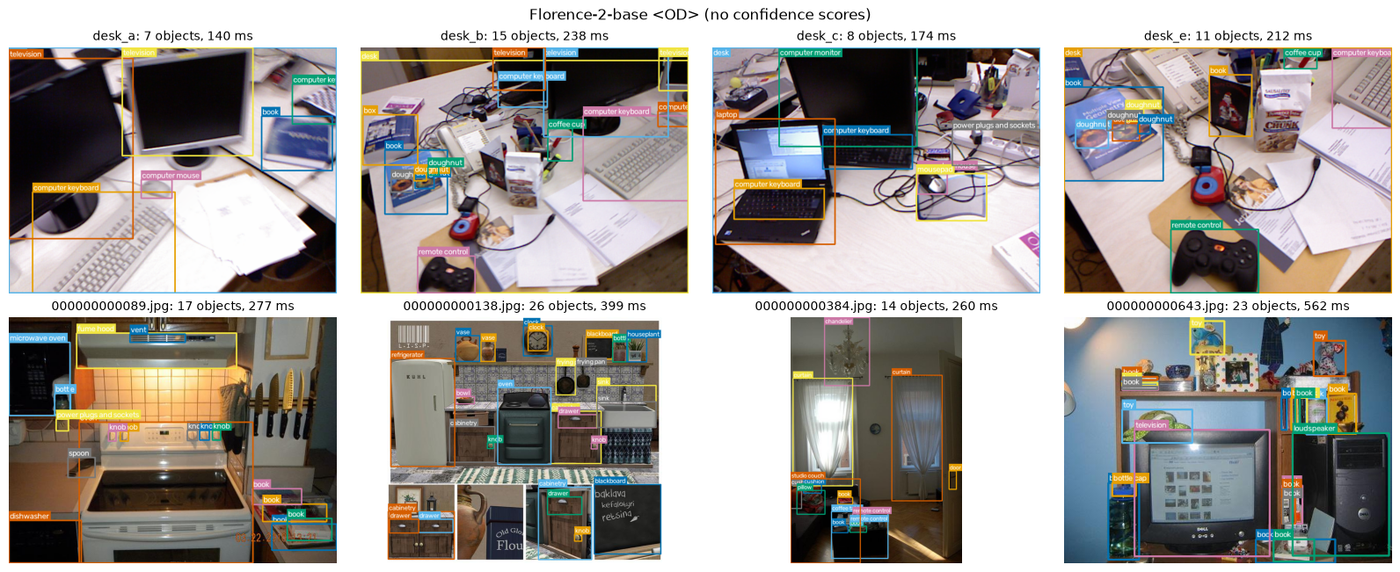

In [5]:
# --- <OD> on four desk frames and four COCO images: box overlays ---
od_keys = ["desk_a", "desk_b", "desk_c", "desk_e"]
coco_pick = [17, 26, 66, 126]  # kitchen, kitchen, living room, office shelf (indices into coco128)
panels, titles = [], []
for img, title in [(desk[k], k) for k in od_keys] + [(vl.load_rgb(coco[i].path), coco[i].path.name) for i in coco_pick]:
    r = fl.run(img, "<OD>")
    panels.append(viz.draw_boxes(np.asarray(img), r.boxes, r.labels))
    titles.append(f"{title}: {len(r.labels)} objects, {r.latency_ms:.0f} ms")
fig_od = viz.show_images(panels, titles, ncols=4, size=4.0, suptitle="Florence-2-base <OD> (no confidence scores)")
plt.show()

### Quantitative check on coco128

Florence-2 gives no scores, so there is no precision-recall curve and no AP. We report
precision and recall at IoU $\geq 0.5$ instead. A prediction is a true positive if its label,
after normalisation to the COCO vocabulary (lower-casing, plurals, a small synonym table such as
"man" to "person" and "computer monitor" to "tv"), equals the label of an unmatched GT box with
IoU $\geq 0.5$:

$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}.$$

Two caveats. Free-text labels outside COCO count as false positives even when they are correct
("desk", "lamp"). And coco128 comes from COCO *train2017*, which is part of Florence-2's
training data, so these numbers are optimistic.

In [6]:
# --- <OD> on all 128 coco128 images: TP/FP/FN at IoU 0.5 with label normalisation ---
det_rows, od_lat, outside, od_results = [], [], [], []
with vl.vram_meter() as mem_od:
    for it in coco:
        r = fl.run(vl.load_rgb(it.path), "<OD>")
        od_results.append(r)  # kept for the per-class analysis below
        od_lat.append(r.latency_ms)
        m = vl.match_by_label(r.boxes, r.labels, it.boxes, it.names())
        det_rows.append({"image": it.path.name, "n_gt": len(it.classes), "n_pred": len(r.labels), **m})
        outside += [lab for lab in r.labels if vl.normalize_label(lab) not in vl.COCO_NAMES]
det = pd.DataFrame(det_rows)
tp, fp, fn = det[["tp", "fp", "fn"]].sum()
od_summary = {"images": len(det), "GT boxes": int(det.n_gt.sum()), "predictions": int(det.n_pred.sum()),
              "precision@0.5": tp / (tp + fp), "recall@0.5": tp / (tp + fn),
              "non-COCO labels": len(outside), "mean latency (ms)": float(np.mean(od_lat)),
              "peak VRAM (MiB)": mem_od.peak_mb}
display(esc(pd.Series(od_summary).to_frame("Florence-2-base <OD> on coco128").T.style.format(precision=3)))
print("most frequent labels outside the COCO vocabulary:", pd.Series(outside).value_counts().head(12).to_dict())

,images,GT boxes,predictions,precision@0.5,recall@0.5,non-COCO labels,mean latency (ms),peak VRAM (MiB)
Florence-2-base <OD> on coco128,128.000,929.000,1119.000,0.466,0.561,347.000,217.784,628.480


most frequent labels outside the COCO vocabulary: {'footwear': 34, 'green onion': 18, 'swimwear': 10, 'wheel': 10, 'drawer': 10, 'kitchen & dining room table': 9, 'button': 9, 'onion': 9, 'knob': 8, 'sparrow': 8, 'bread': 8, 'bull mastiff': 8}


Recall per class shows which COCO categories the model misses or names differently. The
matcher runs once per GT class on the stored outputs, using only the predictions whose
normalised label equals that class.

In [7]:
# --- Per-class recall for classes with >= 10 GT instances (from the stored <OD> outputs) ---
per_cls = {}
for it, r in zip(coco, od_results):
    for c in set(it.names()):
        gt_mask = np.array(it.names()) == c
        pred_mask = np.array([vl.normalize_label(lab) == c for lab in r.labels], dtype=bool)
        m = vl.match_by_label(r.boxes[pred_mask], [c] * pred_mask.sum(), it.boxes[gt_mask], [c] * gt_mask.sum())
        tp_c, n_c = per_cls.get(c, (0, 0))
        per_cls[c] = (tp_c + m["tp"], n_c + int(gt_mask.sum()))
recall_cls = (pd.DataFrame(per_cls, index=["tp", "n_gt"]).T.query("n_gt >= 10")
              .assign(recall=lambda d: d.tp / d.n_gt).sort_values("recall"))
display(recall_cls.style.format({"recall": "{:.1%}"}))

,tp,n_gt,recall
dining table,0,13,0.0%
handbag,2,19,10.5%
traffic light,2,14,14.3%
broccoli,2,11,18.2%
teddy bear,4,21,19.0%
car,10,46,21.7%
kite,3,10,30.0%
knife,5,16,31.2%
spoon,9,22,40.9%
truck,5,12,41.7%


## 6. Phrase grounding for robot instructions

A robot gets instructions such as *"pick up the game controller"*. With
`<CAPTION_TO_PHRASE_GROUNDING>`, Florence-2 localises the noun phrases of a text. We ground
phrases for objects that **are** in the frame and for objects that are **not** (a banana, a cat,
a laptop on the `desk_e` close-up).

In [8]:
# --- Ground present and absent phrases on two desk frames ---
GROUND = {
    "desk_e": ["the game controller", "the telephone", "the blue book", "the computer keyboard",
               "a banana", "a cat", "a laptop"],
    "desk_c": ["the laptop", "the computer mouse", "the mouse pad", "a coffee mug", "a banana"],
}
ABSENT = {("desk_e", "a banana"), ("desk_e", "a cat"), ("desk_e", "a laptop"), ("desk_c", "a banana")}
g_rows = []
for key, phrases in GROUND.items():
    for ph in phrases:
        r = fl.run(desk[key], "<CAPTION_TO_PHRASE_GROUNDING>", ph)
        box = r.boxes[0] if len(r.boxes) else np.full(4, np.nan)
        g_rows.append({"frame": key, "phrase": ph, "in image": (key, ph) not in ABSENT,
                       "n boxes": len(r.boxes), "box": box, "ms": r.latency_ms})
grounding = pd.DataFrame(g_rows)
display(grounding.drop(columns="box").style.format({"ms": "{:.0f}"}))

,frame,phrase,in image,n boxes,ms
0,desk_e,the game controller,True,1,64
1,desk_e,the telephone,True,1,65
2,desk_e,the blue book,True,1,64
3,desk_e,the computer keyboard,True,1,71
4,desk_e,a banana,False,1,64
5,desk_e,a cat,False,1,61
6,desk_e,a laptop,False,1,65
7,desk_c,the laptop,True,1,67
8,desk_c,the computer mouse,True,1,67
9,desk_c,the mouse pad,True,1,68


### Verifying grounded boxes with SigLIP 2

Every phrase got a box, including the absent ones. Grounding answers *"where would this
phrase be?"*, not *"is it there?"*. A cheap fix that a robot pipeline can use is to **verify**
each box with the dual encoder from notebook 01: crop the box (with 10% context) and score the
crop against the phrase with SigLIP 2's sigmoid,
$p = \sigma(t\,\mathbf{x}_\text{crop}^\top\mathbf{y}_\text{phrase} + b)$.

In [9]:
# --- Score each grounded crop against its phrase with SigLIP 2 (sigmoid probability) ---
siglip = vl.SigLIP2Encoder(device)

def crop(img, box, pad=0.1):
    """Crop a PIL image to a box enlarged by `pad` of its size on each side."""
    x1, y1, x2, y2 = box
    dx, dy = pad * (x2 - x1), pad * (y2 - y1)
    return img.crop((max(0, x1 - dx), max(0, y1 - dy), min(img.width, x2 + dx), min(img.height, y2 + dy)))

crops = [crop(desk[f], b) for f, b in zip(grounding.frame, grounding.box)]
x = siglip.encode_images(crops)
y = siglip.encode_texts([f"This is a photo of {ph}." for ph in grounding.phrase])
grounding["SigLIP p(match)"] = vl.zero_shot_scores(x, y, siglip.scale, siglip.bias, "sigmoid").diagonal()
display(grounding.drop(columns="box").style.format({"ms": "{:.0f}", "SigLIP p(match)": "{:.3f}"})
        .background_gradient(subset=["SigLIP p(match)"], cmap="RdYlGn", vmin=0, vmax=1))

,frame,phrase,in image,n boxes,ms,SigLIP p(match)
0,desk_e,the game controller,True,1,64,0.932
1,desk_e,the telephone,True,1,65,0.547
2,desk_e,the blue book,True,1,64,0.044
3,desk_e,the computer keyboard,True,1,71,0.233
4,desk_e,a banana,False,1,64,0.000
5,desk_e,a cat,False,1,61,0.000
6,desk_e,a laptop,False,1,65,0.010
7,desk_c,the laptop,True,1,67,0.655
8,desk_c,the computer mouse,True,1,67,0.757
9,desk_c,the mouse pad,True,1,68,0.799


## 7. Latency, beam search and memory

Beam search keeps the $B$ most likely partial sequences at every step. That is about $B$
times the decoder work, but on a GPU it is batched, so the latency cost is smaller than
$B\times$. We time every task on the five desk frames with greedy decoding ($B=1$) and with the
default $B=3$ (after one warm-up call).

In [10]:
# --- Mean latency and generated tokens per task, greedy vs 3-beam search (5 desk frames) ---
TASKS = ["<CAPTION>", "<DETAILED_CAPTION>", "<MORE_DETAILED_CAPTION>", "<OD>", "<CAPTION_TO_PHRASE_GROUNDING>"]
fl.run(desk["desk_a"], "<CAPTION>")  # warm-up (CUDA kernels, allocator)
lat_rows = []
with vl.vram_meter() as mem_lat:
    for task in TASKS:
        for beams in (1, 3):
            for key, img in desk.items():
                text = "a keyboard and a computer mouse" if task == "<CAPTION_TO_PHRASE_GROUNDING>" else None
                r = fl.run(img, task, text, num_beams=beams)
                lat_rows.append({"task": task, "beams": beams, "frame": key, "ms": r.latency_ms, "tokens": r.n_tokens})
lat = pd.DataFrame(lat_rows).groupby(["task", "beams"])[["ms", "tokens"]].mean().unstack("beams")
display(esc(lat.loc[TASKS].style.format("{:.0f}")))
print(f"peak VRAM (Florence-2 + SigLIP 2 loaded, 3 beams): {mem_lat.peak_mb:.0f} MiB")

peak VRAM (Florence-2 + SigLIP 2 loaded, 3 beams): 1356 MiB


## Results

All numbers come from the cells above (RTX 5060 Laptop GPU, 8 GB, fp16). First, the `<OD>`
overlays from Section 5 and the grounding results, with each box coloured by whether SigLIP 2
accepts it ($p \geq 0.5$, green) or rejects it (red).

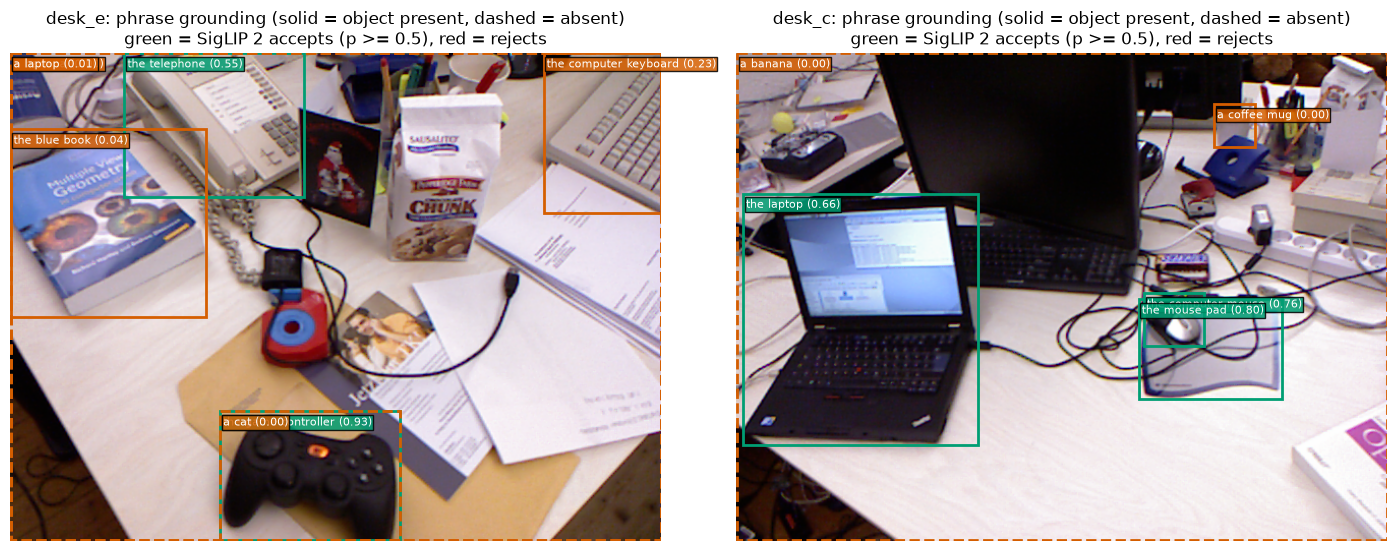

In [11]:
# --- Figures: <OD> overlays (from Section 5) + grounding with SigLIP verification ---
viz.savefig(fig_od, PROJECT, "florence_od")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, key in zip(axes, GROUND):
    sub = grounding[grounding.frame == key]
    ax.imshow(desk[key])
    for _, row in sub.iterrows():
        ok = row["SigLIP p(match)"] >= 0.5
        x1, y1, x2, y2 = row.box
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2,
                                   ec=viz.color(2, unit=True) if ok else viz.color(5, unit=True),
                                   ls="-" if row["in image"] else "--"))
        ax.text(x1 + 3, y1 + 14, f"{row.phrase} ({row['SigLIP p(match)']:.2f})", fontsize=8, color="w",
                bbox={"fc": viz.color(2, unit=True) if ok else viz.color(5, unit=True), "alpha": 0.85, "pad": 1})
    ax.set(title=f"{key}: phrase grounding (solid = object present, dashed = absent)\n"
                 "green = SigLIP 2 accepts (p >= 0.5), red = rejects")
    ax.axis("off")
viz.savefig(fig, PROJECT, "florence_grounding")
plt.show()

# Thumbnail for the root README (~400 px wide): the verified boxes on the desk close-up.
fig, ax = plt.subplots(figsize=(4.2, 3.3))
ax.imshow(desk["desk_e"])
for _, row in grounding[(grounding.frame == "desk_e") & (grounding["SigLIP p(match)"] >= 0.5)].iterrows():
    x1, y1, x2, y2 = row.box
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2.5, ec=viz.color(2, unit=True)))
    ax.text(x1 + 4, y1 + 22, f'"{row.phrase}" p={row["SigLIP p(match)"]:.2f}', fontsize=8, color="w",
            bbox={"fc": viz.color(2, unit=True), "alpha": 0.9, "pad": 1.5})
ax.set_title("Florence-2 phrase grounding, verified by SigLIP 2", fontsize=9)
ax.axis("off")
viz.savefig(fig, PROJECT, "thumb", dpi=100)
plt.close(fig)

Latency per task and decoding strategy (mean over the five desk frames):

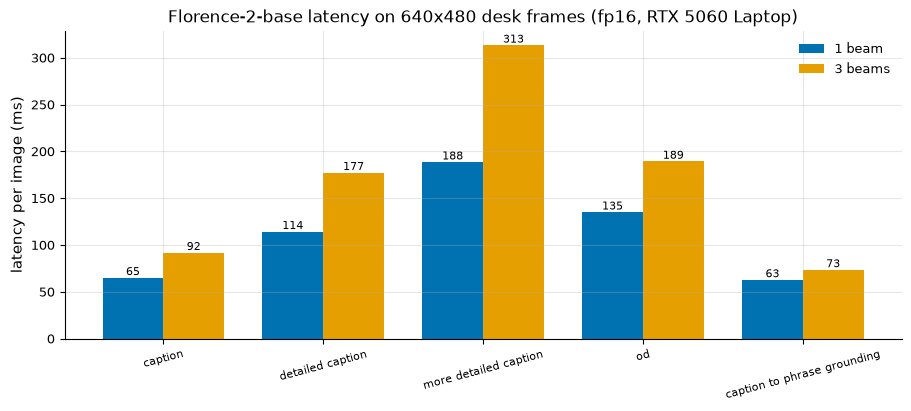

In [12]:
# --- Figure: latency per task, greedy vs beam search ---
fig, ax = plt.subplots(figsize=(9, 4))
ms = lat["ms"].loc[TASKS]
xpos = np.arange(len(TASKS))
for k, beams in enumerate(ms.columns):
    bars = ax.bar(xpos + (k - 0.5) * 0.38, ms[beams], 0.38, label=f"{beams} beam{'s' if beams > 1 else ''}",
                  color=viz.color(k, unit=True))
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_xticks(xpos, [t.strip("<>").replace("_", " ").lower() for t in TASKS], rotation=15, fontsize=8)
ax.set(ylabel="latency per image (ms)", title="Florence-2-base latency on 640x480 desk frames (fp16, RTX 5060 Laptop)")
ax.legend()
viz.savefig(fig, PROJECT, "florence_latency")
plt.show()

### Summary table

The table collects the headline numbers. It is also written to
`results/florence2_summary.csv`.

In [13]:
# --- Summary table of measured numbers (saved as CSV for the README) ---
absent = grounding[~grounding["in image"]]
present = grounding[grounding["in image"]]
summary = pd.DataFrame([
    {"metric": "<OD> precision@0.5 on coco128 (label-normalised)", "value": od_summary["precision@0.5"]},
    {"metric": "<OD> recall@0.5 on coco128 (label-normalised)", "value": od_summary["recall@0.5"]},
    {"metric": "<OD> predictions with non-COCO labels", "value": od_summary["non-COCO labels"]},
    {"metric": "grounding: absent phrases that still got a box", "value": int((absent["n boxes"] > 0).sum())},
    {"metric": "grounding: absent phrases rejected by SigLIP 2 (p < 0.5)", "value": int((absent["SigLIP p(match)"] < 0.5).sum())},
    {"metric": "grounding: present phrases accepted by SigLIP 2 (p >= 0.5)", "value": int((present["SigLIP p(match)"] >= 0.5).sum())},
    {"metric": "<CAPTION> latency, 3 beams (ms)", "value": lat["ms"].loc["<CAPTION>", 3]},
    {"metric": "<OD> latency, 3 beams (ms)", "value": lat["ms"].loc["<OD>", 3]},
    {"metric": "<OD> latency, greedy (ms)", "value": lat["ms"].loc["<OD>", 1]},
    {"metric": "Florence-2 weights (MiB)", "value": mem.delta_mb},
    {"metric": "peak VRAM, <OD> on coco128 (MiB)", "value": od_summary["peak VRAM (MiB)"]},
]).set_index("metric")
summary.to_csv(RESULTS / "florence2_summary.csv", float_format="%.4f")
summary["value"] = summary["value"].astype(object)  # the next row is a string
summary.loc["grounding: phrases tested (absent / present)"] = f"{len(absent)} / {len(present)}"
display(esc(summary.style.format(lambda v: f"{v:.3f}" if isinstance(v, float) and v < 1 else
                                 (f"{v:.0f}" if isinstance(v, float) else v))))

,value
metric,
<OD> precision@0.5 on coco128 (label-normalised),0.466
<OD> recall@0.5 on coco128 (label-normalised),0.561
<OD> predictions with non-COCO labels,347
grounding: absent phrases that still got a box,4
grounding: absent phrases rejected by SigLIP 2 (p < 0.5),4
grounding: present phrases accepted by SigLIP 2 (p >= 0.5),5
"<CAPTION> latency, 3 beams (ms)",92
"<OD> latency, 3 beams (ms)",189
"<OD> latency, greedy (ms)",135


### Takeaways

* **One small model, many tasks.** Florence-2-base (231 M parameters, 452 MiB in fp16) captions,
  detects and grounds phrases; peak VRAM for `<OD>` over coco128 was 628 MiB.
* **Boxes really are just tokens.** Decoding `<loc_k>` by hand with
  $\hat{x} = \lfloor (k + 0.5)\,W/1000 \rfloor$ reproduces the processor's boxes exactly (0.0 px).
* **`<OD>` is useful but not a calibrated detector.** On coco128 it reaches precision 0.466 and
  recall 0.561 at IoU 0.5 (1,119 predictions, 929 GT boxes). 347 predictions carry labels outside
  the COCO vocabulary ("footwear", "green onion", "wheel") and count as false positives, while
  coco128 is part of Florence-2's training data, so the numbers are biased in both directions.
  Some classes are almost never found (dining table 0/13, handbag 2/19, traffic light 2/14). With
  no confidence scores there is no precision-recall trade-off to tune.
* **Grounding is not detection.** All 4 phrases for absent objects still got a box ("a banana"
  on `desk_e` gets the whole frame). Verifying the crop with SigLIP 2 rejected all 4 absent
  phrases ($p \leq 0.010$) but also 3 of the 8 present ones ("the blue book" 0.044, "the computer
  keyboard" 0.233, "a coffee mug" 0.003): verification buys precision at a recall cost.
* **Longer captions hallucinate more.** `<MORE_DETAILED_CAPTION>` on `desk_c` describes "two
  laptops and a desktop computer" (there is one laptop), and on `desk_e` it puts the book title
  on the telephone ("a white telephone with a blue cover that reads 'Multipurpose View Geometry'").
* **Latency follows the number of generated tokens.** With greedy decoding vs 3 beams, `<OD>` took
  135 vs 189 ms and `<CAPTION>` 65 vs 92 ms per 640 x 480 frame;
  phrase grounding (about 10 tokens) took 63-73 ms. Beam search did not
  improve coco128 detection (see Exercise 2).

## Exercises

Solutions: `python projects/13_vision_language/solutions/ex02_florence2.py`.

**Exercise 1: read the book titles.** Run `<OCR_WITH_REGION>` on `desk_e` and draw the
returned quadrilaterals (`FlorenceResult.quads`, 4 corner points per text line). Which lines are
read correctly? How does the result change if you first crop the image to the book's
grounded box and upsample it?

In [14]:
# --- Exercise 1: OCR with regions on the desk close-up ---
# TODO: r = fl.run(desk["desk_e"], "<OCR_WITH_REGION>"); draw r.quads (x1,y1,...,x4,y4) as polygons
# with r.labels; then repeat on the upsampled crop of the grounded "the blue book" box.

**Exercise 2: greedy vs beam search on coco128.** Re-run the coco128 evaluation of Section 5
with `num_beams=1`. How do precision, recall and mean latency change?

In [15]:
# --- Exercise 2: <OD> precision/recall and latency with greedy decoding ---
# TODO: loop over coco128 with fl.run(img, "<OD>", num_beams=1) and recompute TP/FP/FN.

**Exercise 3: a "where is X?" primitive for a robot.** For the instruction *"the game controller"*,
ground the phrase on `desk_e`, verify it with SigLIP 2, take the box centre pixel $(u, v)$,
read the aligned TUM depth $z$ (median of the valid pixels in a 9 x 9 window; dark objects can
leave depth holes, so fall back to the central part of the box) and back-project it to a 3D point in the
camera frame, $\mathbf{X} = z\,K^{-1}[u, v, 1]^\top$ (use `cvlab.tum.load_sequence` for $K$
and the depth file).

In [16]:
# --- Exercise 3: phrase -> verified box -> 3D point in the camera frame ---
# TODO: seq = cvlab.tum.load_sequence(TUM_RGB.parent); find the index of frames["desk_e"];
# depth = seq.depth(i) (metres); X = z * inv(seq.camera.K) @ [u, v, 1].